# TP2 Analyse Big Data des accidents de la route avec PySpark - OZEL IBRAHIM

Objectif : refaire l'étude "Big Data Analysis of Road Crash Data using PySpark with PySpark Tutorial" de Rakesh Nain (Medium), en utilisant les trois façons de travailler avec Spark : les RDD, les DataFrames et Spark SQL.

Les données sont les accidents de la route en Australie-Méridionale entre 2012 et 2019, publiées par le DPTI sur data.sa.gov.au. On utilise deux fichiers par année :
- crash_data : une ligne par accident (lieu, date, gravité, alcool, drogue...)
- units_data : une ligne par véhicule ou piéton impliqué dans un accident (sexe et âge du conducteur, permis...)

Les deux tables se relient avec la colonne REPORT_ID. La description des colonnes se trouve dans data/metadata-for-road-crash.pdf.

Le jour exact de l'accident n'est pas donné, seulement le jour de la semaine. Les dates seront donc écrites sous la forme Année-Mois-Jour, par exemple 2017-January-Sunday.

## 1. Imports et lancement de Spark

Ici Spark tourne sur un seul ordinateur et utilise tous ses cœurs en parallèle. Sur un vrai cluster le code serait le même, il faudrait juste changer le master.

In [1]:
import os, sys, csv, time
import pandas as pd
import matplotlib.pyplot as plt

# Les workers Python de Spark utilisent le même interpréteur que le notebook
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark import SparkConf
from pyspark.sql import SparkSession
from pyspark.rdd import RDD
from pyspark.sql.functions import udf, col
from pyspark.sql.types import IntegerType, StringType
import pyspark.sql.functions as F

CRASH_DIR = "data/crash_data/*.csv"
UNITS_DIR = "data/units_data/*.csv"

Les données (8 fichiers Crash et 8 fichiers Units, environ 77 Mo) viennent du GitHub de l'auteur. Cette cellule les télécharge dans le dossier data si on ne les a pas encore.

In [2]:
import urllib.request

BASE = "https://raw.githubusercontent.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/HEAD"
for annee in range(2012, 2020):
    for dossier, suffixe in [("crash_data", "Crash"), ("units_data", "Units")]:
        chemin = f"data/{dossier}/{annee}_DATA_SA_{suffixe}.csv"
        if not os.path.exists(chemin):
            os.makedirs(os.path.dirname(chemin), exist_ok=True)
            urllib.request.urlretrieve(f"{BASE}/{dossier}/{annee}_DATA_SA_{suffixe}.csv", chemin)
print(len(os.listdir("data/crash_data")), "fichiers crash,", len(os.listdir("data/units_data")), "fichiers units")

8 fichiers crash, 8 fichiers units


In [3]:
# local[*] : autant de threads de travail que de cœurs logiques de la machine
master = "local[*]"
app_name = "Big data Analysis of Road Crash Data"
spark_conf = (SparkConf().setMaster(master).setAppName(app_name)
              .set("spark.ui.showConsoleProgress", "false"))   # pas de barres de progression dans le notebook

spark = SparkSession.builder.config(conf=spark_conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel("ERROR")

print("Spark", spark.version, "| cœurs utilisés :", sc.defaultParallelism)

26/10/16 08:38:03 WARN Utils: Your hostname, DESKTOP-OM3R6OP resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/16 08:38:03 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/16 08:38:04 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.3 | cœurs utilisés : 12


## 2. Analyse avec les RDD

Un RDD (Resilient Distributed Dataset) est une collection de données découpée en plusieurs partitions. Chaque partition peut être traitée par un cœur différent. Un RDD ne se modifie pas, on en crée un nouveau à chaque opération.

Il y a deux types d'opérations :
- les transformations (map, filter, join...) qui ne calculent rien tout de suite, Spark les garde en mémoire
- les actions (collect, count, take...) qui lancent vraiment le calcul

### 2.1 Créer un RDD

On peut créer un RDD à partir d'une liste Python avec parallelize(), ou à partir de fichiers avec textFile().

In [4]:
data_list = [i for i in range(10)]

rdd = sc.parallelize(data_list)              # nombre de partitions par défaut = nombre de threads
print("Partitions par défaut :", rdd.getNumPartitions())

rdd = sc.parallelize(data_list, 5)           # nombre de partitions choisi
print("Partitions manuelles  :", rdd.getNumPartitions())
rdd.collect()

Partitions par défaut : 12
Partitions manuelles  : 5


[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Avec textFile(), chaque ligne du fichier devient un élément du RDD. En mettant *.csv on charge les 8 années d'un seul coup.

In [5]:
units_rdd = sc.textFile(UNITS_DIR)
crash_rdd = sc.textFile(CRASH_DIR)

# Chaque fichier annuel a sa ligne d'en-tête : on les retire toutes
units_header = units_rdd.first()
units_rdd = units_rdd.filter(lambda row: row != units_header)
crash_header = crash_rdd.first()
crash_rdd = crash_rdd.filter(lambda row: row != crash_header)

print("Nombre d'unités    :", units_rdd.count())
print("Nombre d'accidents :", crash_rdd.count())
units_rdd.take(3)

Nombre d'unités    : 272591


Nombre d'accidents : 127672


['"2012-1-21/08/2019","01",0,,"Pedal Cycle",,"South West","Male","035",,,,,"Straight Ahead","001","5074",,',
 '"2012-1-21/08/2019","02",0,"SA","Motor Cars - Sedan","2009","North West","Female","050","SA","C ","Full","Unknown","Leaving Private Driveway","001","5089",,',
 '"2012-2-21/08/2019","01",0,"SA","Motor Cars - Sedan","1999","West","Male","027","SA",,"Provisional 1 ","Not Towing","Straight Ahead","002","5008",,']

Pour l'instant chaque ligne est juste une chaîne de caractères. On la découpe avec le module csv plutôt qu'avec split(','), sinon une virgule à l'intérieur de guillemets casserait la ligne. On garde aussi les noms des colonnes pour pouvoir écrire r[U["Sex"]] au lieu de compter les indices à la main.

In [6]:
def parse_csv(line):
    return next(csv.reader([line]))

UNITS_COLS = parse_csv(units_header)
CRASH_COLS = parse_csv(crash_header)
U = {nom: i for i, nom in enumerate(UNITS_COLS)}   # nom de colonne -> indice
C = {nom: i for i, nom in enumerate(CRASH_COLS)}

units_parsed = units_rdd.map(parse_csv)
crash_parsed = crash_rdd.map(parse_csv)

print("Colonnes units :", UNITS_COLS)
print("\nColonnes crash :", CRASH_COLS)

Colonnes units : ['REPORT_ID', 'Unit No', 'No Of Cas', 'Veh Reg State', 'Unit Type', 'Veh Year', 'Direction Of Travel', 'Sex', 'Age', 'Lic State', 'Licence Class', 'Licence Type', 'Towing', 'Unit Movement', 'Number Occupants', 'Postcode', 'Rollover', 'Fire']

Colonnes crash : ['REPORT_ID', 'Stats Area', 'Suburb', 'Postcode', 'LGA Name', 'Total Units', 'Total Cas', 'Total Fats', 'Total SI', 'Total MI', 'Year', 'Month', 'Day', 'Time', 'Area Speed', 'Position Type', 'Horizontal Align', 'Vertical Align', 'Other Feat', 'Road Surface', 'Moisture Cond', 'Weather Cond', 'DayNight', 'Crash Type', 'Unit Resp', 'Entity Code', 'CSEF Severity', 'Traffic Ctrls', 'DUI Involved', 'Drugs Involved', 'ACCLOC_X', 'ACCLOC_Y', 'UNIQUE_LOC']


### 2.2 Partitionnement

Par défaut, Spark répartit les lignes à peu près équitablement entre les partitions :

In [7]:
print("Units : ", units_rdd.getNumPartitions(), "partitions")
print("Crash : ", crash_rdd.getNumPartitions(), "partitions")

Units :  8 partitions
Crash :  8 partitions


On peut aussi choisir nous-mêmes comment répartir les données. Comme dans l'article, on met les véhicules immatriculés en Australie-Méridionale (SA) dans la partition 0 et tous les autres dans la partition 1.

Pour ça il faut un RDD de paires (clé, valeur). La clé est l'état d'immatriculation (Veh Reg State) et la valeur est le reste de la ligne.

In [8]:
units_state_rdd = units_parsed.map(
    lambda r: (r[U["Veh Reg State"]], [x for i, x in enumerate(r) if i != U["Veh Reg State"]]))

def hash_SA(key):
    return 0 if key == "SA" else 1

SA_partitioned_rdd = units_state_rdd.partitionBy(2, hash_SA)

def print_partitions(data):
    rdd = data if isinstance(data, RDD) else data.rdd
    print("NOMBRE DE PARTITIONS :", rdd.getNumPartitions())
    for index, taille in enumerate(rdd.glom().map(len).collect()):
        print(f"Partition {index} : {taille} enregistrements")

print_partitions(SA_partitioned_rdd)

NOMBRE DE PARTITIONS : 2


Partition 0 : 218366 enregistrements
Partition 1 : 54225 enregistrements


glom() regroupe chaque partition dans une liste. On ne récupère que la taille de chaque liste, alors que l'article faisait glom().collect() et ramenait toutes les données.

On voit qu'environ 80 % des véhicules sont immatriculés en SA, ce qui est normal vu que les données viennent de cet État.

### 2.3 Requêtes avec les RDD

Âge moyen des conducteurs hommes et femmes. On enlève les âges inconnus (XXX ou vide) et le sexe Unknown.

In [9]:
def parse_gender_age(r):
    sexe, age = r[U["Sex"]], r[U["Age"]]
    if age not in ("XXX", "") and sexe in ("Male", "Female"):
        return (sexe, int(age))

gender_age_rdd = units_parsed.map(parse_gender_age).filter(lambda x: x is not None)

# (somme, nombre) par sexe avec reduceByKey : évite de regrouper toutes les valeurs comme groupByKey
gender_age_avg = (gender_age_rdd
                  .mapValues(lambda age: (age, 1))
                  .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
                  .mapValues(lambda s: round(s[0] / s[1], 2)))
gender_age_avg.collect()

[('Male', 40.8), ('Female', 40.08)]

Les hommes et les femmes ont presque le même âge moyen, autour de 40 ans.

Ensuite on cherche l'état d'immatriculation et le type des véhicules les plus vieux et les plus récents.

In [10]:
def parse_year(r):
    annee = r[U["Veh Year"]]
    if annee not in ("XXXX", ""):
        return int(annee), [r[U["Veh Reg State"]], r[U["Unit Type"]]]

year_rdd = units_parsed.map(parse_year).filter(lambda x: x is not None)

# takeOrdered ne rapatrie que les 5 premiers éléments (au lieu de trier puis tout collecter)
print("5 véhicules les plus anciens :\n", year_rdd.takeOrdered(5, key=lambda x: x[0]))
print("\n5 véhicules les plus récents :\n", year_rdd.takeOrdered(5, key=lambda x: -x[0]))

5 véhicules les plus anciens :
 [(1900, ['VIC', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle']), (1900, ['SA', 'Motor Cycle'])]



5 véhicules les plus récents :
 [(2019, ['SA', 'Station Wagon']), (2019, ['SA', 'OMNIBUS']), (2019, ['SA', 'Motor Cars - Sedan']), (2019, ['SA', 'Station Wagon']), (2019, ['SA', 'SEMI TRAILER'])]


Des motos de 1900, ça paraît peu probable. Je pense que 1900 a été mis quand l'année n'était pas connue, donc il faut faire attention à ce genre de valeurs dans les données.

## 3. Analyse avec les DataFrames

Un DataFrame ressemble à une table SQL ou à un DataFrame pandas : les données sont rangées en colonnes avec des noms. La différence avec pandas, c'est qu'il est réparti sur plusieurs partitions et que Spark optimise les requêtes tout seul.

### 3.1 Créer un DataFrame

In [11]:
df = spark.createDataFrame(
    [(1, "Aaditya", "A"), (2, "Chinnavit", "C"), (3, "Neha", "N"), (4, "Huashun", "H"), (5, "Mohammad", "M"),
     (10, "Prajwol", "P"), (1, "Paras", "P"), (1, "Tooba", "T"), (3, "David", "D"), (4, "Cheng", "C"), (9, "Haqqani", "H")],
    ["Id", "Name", "Initial"])
df.show(5)
df.printSchema()

+---+---------+-------+
| Id|     Name|Initial|
+---+---------+-------+
|  1|  Aaditya|      A|
|  2|Chinnavit|      C|
|  3|     Neha|      N|
|  4|  Huashun|      H|
|  5| Mohammad|      M|
+---+---------+-------+
only showing top 5 rows

root
 |-- Id: long (nullable = true)
 |-- Name: string (nullable = true)
 |-- Initial: string (nullable = true)



Pour les accidents on lit directement les CSV avec spark.read. La première ligne sert de noms de colonnes. Toutes les colonnes sont lues comme du texte, donc on convertit en entier celles dont on a besoin pour faire des calculs.

In [12]:
units_df = (spark.read.format("csv")
            .option("header", True).option("escape", '"')
            .load(UNITS_DIR))
crash_df = (spark.read.format("csv")
            .option("header", True).option("escape", '"')
            .load(CRASH_DIR))

# Colonnes numériques utilisées dans les calculs
crash_df = (crash_df.withColumn("Total Cas", col("Total Cas").cast(IntegerType()))
                    .withColumn("Total Fats", col("Total Fats").cast(IntegerType())))

print("units_df :", units_df.count(), "lignes,", len(units_df.columns), "colonnes")
print("crash_df :", crash_df.count(), "lignes,", len(crash_df.columns), "colonnes")
crash_df.select("REPORT_ID", "Suburb", "Year", "Month", "Day", "Time", "Total Cas", "Crash Type", "CSEF Severity").show(5)

units_df : 272591 lignes, 18 colonnes


crash_df : 127672 lignes, 33 colonnes


+-----------------+--------------+----+-------+---------+--------+---------+------------------+-------------+
|        REPORT_ID|        Suburb|Year|  Month|      Day|    Time|Total Cas|        Crash Type|CSEF Severity|
+-----------------+--------------+----+-------+---------+--------+---------+------------------+-------------+
|2012-1-21/08/2019|       STEPNEY|2012|January|   Sunday|04:30 pm|        0|       Right Angle|       1: PDO|
|2012-2-21/08/2019|      PARKSIDE|2012|January|   Sunday|09:10 am|        0|Hit Parked Vehicle|       1: PDO|
|2012-3-21/08/2019|SELLICKS BEACH|2012|January|Wednesday|11:30 am|        0|             Other|       1: PDO|
|2012-4-21/08/2019|     HINDMARSH|2012|January|Wednesday|10:20 am|        0|          Rear End|       1: PDO|
|2012-5-21/08/2019|     HINDMARSH|2012|January|Wednesday|03:30 pm|        0|          Rear End|       1: PDO|
+-----------------+--------------+----+-------+---------+--------+---------+------------------+-------------+
only showi

### 3.2 Requêtes avec les DataFrames

Question 1 : les accidents à Adelaide avec plus de 3 victimes.

In [13]:
adelaide_crash_casualty_df = crash_df.filter(col("Total Cas") > 3).filter(col("Suburb") == "ADELAIDE")
adelaide_crash_casualty_df.select("REPORT_ID", "Year", "Month", "Day", "Time", "Total Cas", "Crash Type", "CSEF Severity").show()

+--------------------+----+--------+--------+--------+---------+--------------+-------------+
|           REPORT_ID|Year|   Month|     Day|    Time|Total Cas|    Crash Type|CSEF Severity|
+--------------------+----+--------+--------+--------+---------+--------------+-------------+
|2012-4842-21/08/2019|2012|   March|Thursday|04:00 pm|        4|      Rear End|        2: MI|
|2012-5769-21/08/2019|2012|   March|  Friday|09:30 am|        4|   Right Angle|        2: MI|
| 2018-601-17/01/2020|2018| January|  Sunday|09:12 pm|        4|Hit Pedestrian|        3: SI|
|2017-1613-15/08/2019|2017|February|Saturday|04:00 pm|        4|    Right Turn|        2: MI|
|2017-12182-15/08/...|2017|December|Saturday|04:08 pm|        5|Hit Pedestrian|        3: SI|
|2019-10404-8/07/2020|2019| October|  Monday|08:20 am|        6|    Right Turn|        2: MI|
+--------------------+----+--------+--------+--------+---------+--------------+-------------+



Question 2 : les 10 accidents avec le plus de victimes.

In [14]:
(crash_df.sort(col("Total Cas"), ascending=False)
         .select("REPORT_ID", "Suburb", "Year", "Month", "Day", "Total Cas", "Total Fats", "Crash Type")
         .show(10))

+--------------------+-------------+----+--------+---------+---------+----------+-----------+
|           REPORT_ID|       Suburb|Year|   Month|      Day|Total Cas|Total Fats| Crash Type|
+--------------------+-------------+----+--------+---------+---------+----------+-----------+
| 2017-288-15/08/2019|   PARA HILLS|2017| January|Wednesday|       11|         0|Right Angle|
|2016-3035-15/08/2019|      HACKHAM|2016| January| Saturday|        9|         3| Right Turn|
|2014-9004-21/08/2019|          APY|2014|    July|   Friday|        9|         1|  Roll Over|
|2016-6630-15/08/2019|KANGAROO FLAT|2016|   April|Wednesday|        9|         0|    Head On|
|2019-11734-8/07/2020|        STURT|2019|November|   Sunday|        9|         0| Right Turn|
|2014-14065-21/08/...|MODBURY NORTH|2014|November|  Tuesday|        9|         0|   Rear End|
| 2012-890-21/08/2019|      KULPARA|2012| January|   Sunday|        8|         1|    Head On|
|2016-7073-15/08/2019|     MERRITON|2016|   April|   Sunday|

Question 3 : le nombre de morts par type d'accident.

In [15]:
fats_by_type_df = (crash_df.groupBy("Crash Type")
                           .agg(F.sum("Total Fats").alias("Total fatalities"))
                           .sort(col("Total fatalities"), ascending=False))
fats_by_type_df.show(truncate=False)

+--------------------------+----------------+
|Crash Type                |Total fatalities|
+--------------------------+----------------+
|Hit Fixed Object          |245             |
|Head On                   |136             |
|Hit Pedestrian            |109             |
|Roll Over                 |93              |
|Right Angle               |82              |
|Rear End                  |33              |
|Side Swipe                |30              |
|Right Turn                |26              |
|Hit Parked Vehicle        |10              |
|Hit Animal                |7               |
|Other                     |5               |
|Left Road - Out of Control|3               |
|Hit Object on Road        |2               |
+--------------------------+----------------+



Ce sont les accidents contre un obstacle fixe (arbre, poteau...) qui font le plus de morts, puis les chocs frontaux et les piétons renversés.

Question 4 : le nombre de victimes par quartier quand le conducteur n'avait pas de permis.

Ici on doit faire une jointure entre les deux tables sur REPORT_ID, car le type de permis est dans units et le quartier est dans crash.

In [16]:
complete_df = crash_df.join(units_df, on="REPORT_ID", how="inner")

by_suburb_no_lic_df = (complete_df.filter(col("Licence Type") == "Unlicenced")
                                  .groupBy("Suburb")
                                  .agg(F.sum("Total Cas").alias("Total casualty"))
                                  .sort(col("Total casualty"), ascending=False))
by_suburb_no_lic_df.show(10)

+--------------+--------------+
|        Suburb|Total casualty|
+--------------+--------------+
|      ADELAIDE|            43|
|     SALISBURY|            30|
|      PROSPECT|            27|
|    INGLE FARM|            22|
|SALISBURY EAST|            20|
| MORPHETT VALE|            20|
| MURRAY BRIDGE|            19|
|     DRY CREEK|            19|
|NORTH ADELAIDE|            17|
|  MAWSON LAKES|            17|
+--------------+--------------+
only showing top 10 rows



On retrouve en premier le centre-ville d'Adelaide, puis des quartiers du nord comme Salisbury, Prospect et Ingle Farm.

### 3.3 Gravité des accidents avec l'alcool et la drogue

La colonne CSEF Severity donne la gravité de l'accident :

| Code | Signification |
|---|---|
| 1: PDO | dégâts matériels seulement |
| 2: MI | blessés légers |
| 3: SI | blessés graves |
| 4: Fatal | au moins un mort |

DUI Involved vaut Y quand un conducteur avait bu, et Drugs Involved vaut Y quand il était positif à la drogue. Sinon la case est vide. On veut voir si les accidents sont plus graves dans ces cas-là.

In [17]:
severe_df = crash_df.groupBy("CSEF Severity").agg(F.count("REPORT_ID").alias("Total accidents")).sort("CSEF Severity")
severe_df.show()

+-------------+---------------+
|CSEF Severity|Total accidents|
+-------------+---------------+
|       1: PDO|          84775|
|        2: MI|          37300|
|        3: SI|           4875|
|     4: Fatal|            722|
+-------------+---------------+



On regarde 4 cas : drogue, alcool, les deux, et ni l'un ni l'autre. Pour chaque cas on compte les accidents par gravité et on calcule le pourcentage.

Dans l'article le pourcentage est calculé avec une UDF (une fonction Python appliquée par Spark). Je la fais une fois pour le cas drogue, puis j'utilise les fonctions de Spark directement, ce qui est plus rapide.

In [18]:
# a) Conducteur positif aux drogues - version avec UDF comme dans l'article
severe_on_drugs_df = (crash_df.filter(col("Drugs Involved") == "Y")
                              .groupBy("CSEF Severity")
                              .agg(F.count("REPORT_ID").alias("Total accidents")))
total_on_drugs = severe_on_drugs_df.agg(F.sum("Total accidents")).collect()[0][0]

def find_severe_percent(s):
    return str(round(int(s) / total_on_drugs * 100, 2)) + "%"

find_severe_percent_udf = udf(find_severe_percent, StringType())
severe_on_drugs_df.withColumn("percent_share", find_severe_percent_udf("Total accidents")).sort("CSEF Severity").show()

+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|            237|       12.78%|
|        2: MI|           1109|       59.82%|
|        3: SI|            391|       21.09%|
|     4: Fatal|            117|        6.31%|
+-------------+---------------+-------------+



In [19]:
# Version générique avec les fonctions natives (fenêtre sur tout le DataFrame pour le total)
from pyspark.sql import Window

def gravite_pct(df_filtre):
    counts = df_filtre.groupBy("CSEF Severity").agg(F.count("REPORT_ID").alias("Total accidents"))
    total = F.sum("Total accidents").over(Window.partitionBy())
    return counts.withColumn("percent_share", F.round(col("Total accidents") / total * 100, 2)).sort("CSEF Severity")

DRUGS = col("Drugs Involved") == "Y"
ALCOOL = col("DUI Involved") == "Y"
AUCUN = col("Drugs Involved").isNull() & col("DUI Involved").isNull()   # champ vide -> null à la lecture

scenarios = {
    "a) Drogues": DRUGS,
    "b) Alcool": ALCOOL,
    "c) Alcool ET drogues": DRUGS & ALCOOL,
    "d) Ni alcool ni drogues": AUCUN,
}
for nom, condition in scenarios.items():
    print(nom)
    gravite_pct(crash_df.filter(condition)).show()

a) Drogues


+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|            237|        12.78|
|        2: MI|           1109|        59.82|
|        3: SI|            391|        21.09|
|     4: Fatal|            117|         6.31|
+-------------+---------------+-------------+

b) Alcool


+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|           2144|        53.88|
|        2: MI|           1243|        31.24|
|        3: SI|            456|        11.46|
|     4: Fatal|            136|         3.42|
+-------------+---------------+-------------+

c) Alcool ET drogues


+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|             36|        12.08|
|        2: MI|            151|        50.67|
|        3: SI|             72|        24.16|
|     4: Fatal|             39|        13.09|
+-------------+---------------+-------------+

d) Ni alcool ni drogues


+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|          82430|        67.49|
|        2: MI|          35099|        28.74|
|        3: SI|           4100|         3.36|
|     4: Fatal|            508|         0.42|
+-------------+---------------+-------------+



On met les 4 cas dans un seul tableau (jointure sur CSEF Severity), une fois en nombre d'accidents et une fois en pourcentage, pour pouvoir les comparer et faire les graphiques.

In [20]:
noms_courts = {"a) Drogues": "On Drugs", "b) Alcool": "On Alcohol",
               "c) Alcool ET drogues": "On Both", "d) Ni alcool ni drogues": "On None"}

all_df, all_df_per = None, None
for nom, condition in scenarios.items():
    g = gravite_pct(crash_df.filter(condition))
    nb = g.select("CSEF Severity", col("Total accidents").alias(noms_courts[nom]))
    pc = g.select("CSEF Severity", col("percent_share").alias(noms_courts[nom]))
    all_df = nb if all_df is None else all_df.join(nb, "CSEF Severity")
    all_df_per = pc if all_df_per is None else all_df_per.join(pc, "CSEF Severity")

all_df = all_df.sort("CSEF Severity")
all_df_per = all_df_per.sort("CSEF Severity")
print("Nombre d'accidents :"); all_df.show()
print("Pourcentage par scénario :"); all_df_per.show()

Nombre d'accidents :


+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|       1: PDO|     237|      2144|     36|  82430|
|        2: MI|    1109|      1243|    151|  35099|
|        3: SI|     391|       456|     72|   4100|
|     4: Fatal|     117|       136|     39|    508|
+-------------+--------+----------+-------+-------+

Pourcentage par scénario :


+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|       1: PDO|   12.78|     53.88|  12.08|  67.49|
|        2: MI|   59.82|     31.24|  50.67|  28.74|
|        3: SI|   21.09|     11.46|  24.16|   3.36|
|     4: Fatal|    6.31|      3.42|  13.09|   0.42|
+-------------+--------+----------+-------+-------+



### 3.4 Graphiques

Spark ne fait pas de graphiques, donc on passe le résultat en pandas avec toPandas() pour utiliser matplotlib.

Il faut faire attention avec toPandas() : toutes les données sont ramenées sur une seule machine. Sur une grosse table ça peut remplir la mémoire. Ici ce n'est pas un problème parce qu'on convertit seulement le tableau final de 4 lignes.

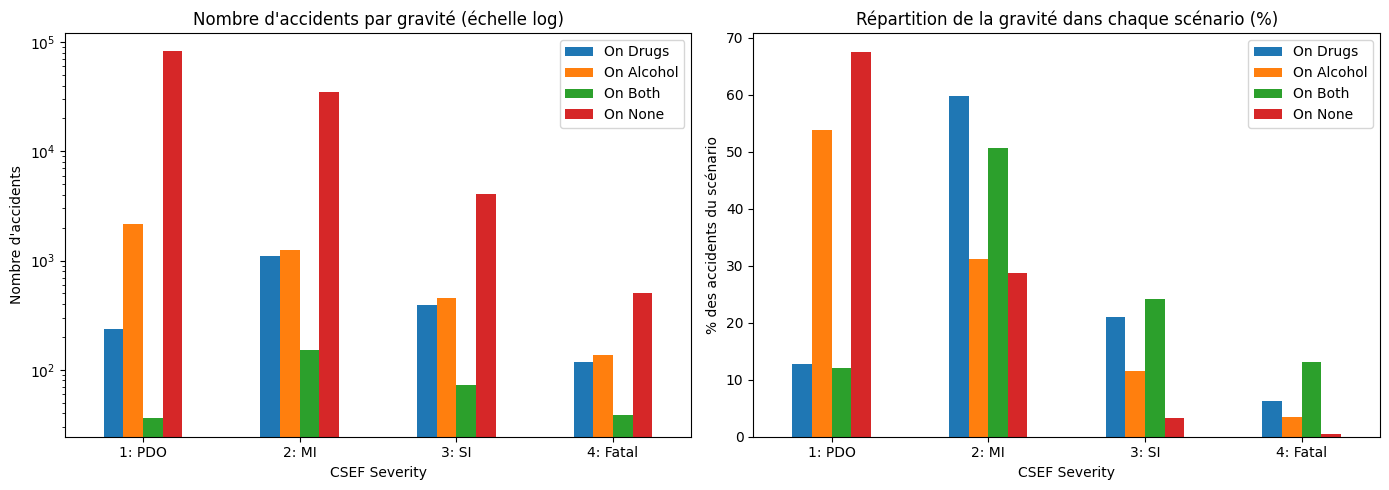

In [21]:
pd_df = all_df.toPandas().set_index("CSEF Severity")
pd_df_per = all_df_per.toPandas().set_index("CSEF Severity")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd_df.plot(kind="bar", ax=axes[0], logy=True, rot=0)
axes[0].set_title("Nombre d'accidents par gravité (échelle log)")
axes[0].set_ylabel("Nombre d'accidents")

pd_df_per.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Répartition de la gravité dans chaque scénario (%)")
axes[1].set_ylabel("% des accidents du scénario")
plt.tight_layout()
plt.show()

Ce qu'on remarque :
- Sans alcool ni drogue, les deux tiers des accidents font seulement des dégâts matériels, et 0,4 % sont mortels.
- Avec de l'alcool, on passe à 3,4 % d'accidents mortels, donc environ 8 fois plus.
- Avec de la drogue, il n'y a plus que 13 % d'accidents sans blessé, et 6 % sont mortels.
- Avec les deux en même temps, 13 % des accidents sont mortels, c'est environ 30 fois plus que sans rien.

Les accidents sont donc nettement plus graves quand le conducteur a bu ou pris de la drogue. Il faut quand même nuancer : on fait sûrement moins de dépistages sur les petits accidents que sur les accidents graves, ce qui peut grossir un peu l'écart.

## 4. Comparaison RDD, DataFrame et Spark SQL

On peut écrire la même requête de trois façons avec Spark. On le fait pour deux questions et on vérifie que les trois versions donnent bien le même résultat. Pour utiliser SQL, il faut d'abord déclarer les DataFrames comme des tables.

In [22]:
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")

# RDD clé-valeur (REPORT_ID, ligne) pour les jointures RDD
units_kv = units_parsed.map(lambda r: (r[0], r))
crash_kv = crash_parsed.map(lambda r: (r[0], r))

### 4.1 Les accidents dans le quartier d'Adelaide

Pour chaque véhicule impliqué on affiche la date, l'heure, le nombre de victimes de l'accident, et le sexe, l'âge et le permis du conducteur.

In [23]:
# --- RDD
def parse_adelaide(kv):
    u, c = kv[1]
    if c[C["Suburb"]] == "ADELAIDE":
        date = c[C["Year"]] + "-" + c[C["Month"]] + "-" + c[C["Day"]]
        return (date, c[C["Time"]], int(c[C["Total Cas"]]), u[U["Sex"]], u[U["Age"]], u[U["Licence Type"]], c[C["Suburb"]])

t0 = time.perf_counter()
adelaide_rdd = units_kv.join(crash_kv).map(parse_adelaide).filter(lambda x: x is not None)
res_rdd = adelaide_rdd.collect()
t_rdd = time.perf_counter() - t0
print(f"RDD       : {len(res_rdd)} lignes en {t_rdd:.2f} s")
res_rdd[:5]

RDD       : 11965 lignes en 5.61 s


[('2012-February-Wednesday', '06:00 pm', 1, 'Male', '044', 'Full', 'ADELAIDE'),
 ('2012-February-Wednesday',
  '06:00 pm',
  1,
  'Male',
  '026',
  'Unknown',
  'ADELAIDE'),
 ('2012-February-Wednesday',
  '06:00 pm',
  1,
  'Female',
  'XXX',
  'Unknown',
  'ADELAIDE'),
 ('2012-June-Friday', '08:00 pm', 0, 'Female', '025', 'Full', 'ADELAIDE'),
 ('2012-June-Friday', '08:00 pm', 0, 'Male', '024', '', 'ADELAIDE')]

In [24]:
# --- DataFrame
t0 = time.perf_counter()
adelaide_df = (crash_df.join(units_df, on="REPORT_ID", how="inner")
                       .filter(col("Suburb") == "ADELAIDE")
                       .withColumn("Date", F.concat_ws("-", "Year", "Month", "Day"))
                       .select("Date", "Time", "Total Cas", "Sex", "Age", "Licence Type", "Suburb"))
res_df = adelaide_df.collect()
t_df = time.perf_counter() - t0
print(f"DataFrame : {len(res_df)} lignes en {t_df:.2f} s")
adelaide_df.show(5)

DataFrame : 11965 lignes en 1.33 s


+-------------------+--------+---------+------+---+-------------+--------+
|               Date|    Time|Total Cas|   Sex|Age| Licence Type|  Suburb|
+-------------------+--------+---------+------+---+-------------+--------+
|2012-January-Monday|08:45 am|        0|  Male|084|         Full|ADELAIDE|
|2012-January-Monday|08:45 am|        0|  Male|040|         Full|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|  Male|047|         Full|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|  Male|XXX|         NULL|ADELAIDE|
|2012-January-Friday|07:30 pm|        1|Female|018|Provisional 2|ADELAIDE|
+-------------------+--------+---------+------+---+-------------+--------+
only showing top 5 rows



In [25]:
# --- Spark SQL
t0 = time.perf_counter()
adelaide_sql = spark.sql('''
    SELECT (Year || '-' || Month || '-' || Day) AS Date, Time, `Total Cas`, Sex, Age, `Licence Type`, Suburb
    FROM units_table u JOIN crash_table c ON u.REPORT_ID = c.REPORT_ID
    WHERE c.Suburb = 'ADELAIDE'
''')
res_sql = adelaide_sql.collect()
t_sql = time.perf_counter() - t0
print(f"Spark SQL : {len(res_sql)} lignes en {t_sql:.2f} s")
adelaide_sql.show(5)

Spark SQL : 11965 lignes en 1.26 s


+-------------------+--------+---------+------+---+-------------+--------+
|               Date|    Time|Total Cas|   Sex|Age| Licence Type|  Suburb|
+-------------------+--------+---------+------+---+-------------+--------+
|2012-January-Monday|08:45 am|        0|  Male|084|         Full|ADELAIDE|
|2012-January-Monday|08:45 am|        0|  Male|040|         Full|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|  Male|047|         Full|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|  Male|XXX|         NULL|ADELAIDE|
|2012-January-Friday|07:30 pm|        1|Female|018|Provisional 2|ADELAIDE|
+-------------------+--------+---------+------+---+-------------+--------+
only showing top 5 rows



In [26]:
# Vérification : les 3 méthodes renvoient exactement les mêmes lignes
# (dans le CSV, une case vide est "" pour le RDD mais null pour le DataFrame : on harmonise)
norm = lambda rows: sorted(tuple("" if v is None else str(v) for v in r) for r in rows)
print("RDD == DataFrame :", norm(res_rdd) == norm(res_df))
print("DataFrame == SQL :", norm(res_df) == norm(res_sql))

RDD == DataFrame : True
DataFrame == SQL : True


### 4.2 Victimes par quartier avec un conducteur sans permis

C'est la même question que la question 4 de la partie 3, mais écrite des trois façons.

In [27]:
# --- RDD
t0 = time.perf_counter()
no_lic_rdd = (units_kv.join(crash_kv)
                      .filter(lambda kv: kv[1][0][U["Licence Type"]] == "Unlicenced")
                      .map(lambda kv: (kv[1][1][C["Suburb"]], int(kv[1][1][C["Total Cas"]])))
                      .reduceByKey(lambda a, b: a + b))
res_rdd2 = no_lic_rdd.collect()
t_rdd2 = time.perf_counter() - t0
print(f"RDD : {len(res_rdd2)} quartiers en {t_rdd2:.2f} s")
sorted(res_rdd2, key=lambda x: -x[1])[:10]

RDD : 752 quartiers en 4.35 s


[('ADELAIDE', 43),
 ('SALISBURY', 30),
 ('PROSPECT', 27),
 ('INGLE FARM', 22),
 ('SALISBURY EAST', 20),
 ('MORPHETT VALE', 20),
 ('MURRAY BRIDGE', 19),
 ('DRY CREEK', 19),
 ('MAWSON LAKES', 17),
 ('NORTH ADELAIDE', 17)]

In [28]:
# --- DataFrame
t0 = time.perf_counter()
no_lic_df = (crash_df.join(units_df, on="REPORT_ID")
                     .filter(col("Licence Type") == "Unlicenced")
                     .groupBy("Suburb").agg(F.sum("Total Cas").alias("Total casualty")))
res_df2 = no_lic_df.collect()
t_df2 = time.perf_counter() - t0
print(f"DataFrame : {len(res_df2)} quartiers en {t_df2:.2f} s")

# --- Spark SQL
t0 = time.perf_counter()
no_lic_sql = spark.sql('''
    SELECT Suburb, SUM(`Total Cas`) AS `Total casualty`
    FROM units_table u JOIN crash_table c ON u.REPORT_ID = c.REPORT_ID
    WHERE `Licence Type` = 'Unlicenced'
    GROUP BY Suburb
    ORDER BY `Total casualty` DESC
''')
res_sql2 = no_lic_sql.collect()
t_sql2 = time.perf_counter() - t0
print(f"Spark SQL : {len(res_sql2)} quartiers en {t_sql2:.2f} s")
no_lic_sql.show(10)

print("RDD == DataFrame :", sorted(res_rdd2) == sorted(map(tuple, res_df2)))
print("DataFrame == SQL :", sorted(map(tuple, res_df2)) == sorted(map(tuple, res_sql2)))

DataFrame : 752 quartiers en 1.09 s


Spark SQL : 752 quartiers en 1.29 s


+--------------+--------------+
|        Suburb|Total casualty|
+--------------+--------------+
|      ADELAIDE|            43|
|     SALISBURY|            30|
|      PROSPECT|            27|
|    INGLE FARM|            22|
|SALISBURY EAST|            20|
| MORPHETT VALE|            20|
| MURRAY BRIDGE|            19|
|     DRY CREEK|            19|
|NORTH ADELAIDE|            17|
|  MAWSON LAKES|            17|
+--------------+--------------+
only showing top 10 rows

RDD == DataFrame : True
DataFrame == SQL : True


                  RDD  DataFrame  Spark SQL
4.1 Adelaide     5.61       1.33       1.26
4.2 Sans permis  4.35       1.09       1.29


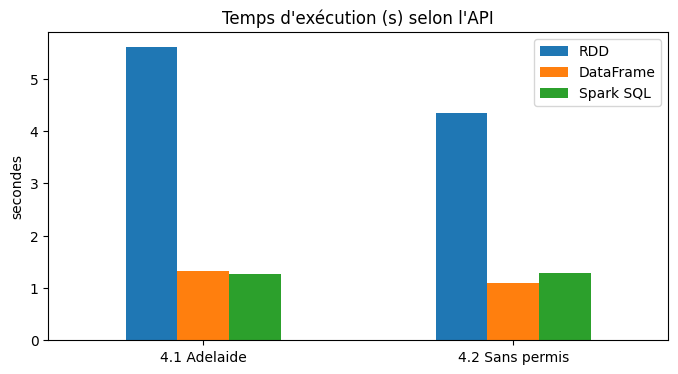

In [29]:
temps = pd.DataFrame({"RDD": [t_rdd, t_rdd2], "DataFrame": [t_df, t_df2], "Spark SQL": [t_sql, t_sql2]},
                     index=["4.1 Adelaide", "4.2 Sans permis"]).round(2)
print(temps)
temps.plot(kind="bar", rot=0, figsize=(8, 4), title="Temps d'exécution (s) selon l'API")
plt.ylabel("secondes")
plt.show()

Les DataFrames et Spark SQL ont des temps proches, ce qui est logique car Spark les transforme en la même requête optimisée. Les RDD sont plus lents : chaque ligne doit passer par Python et Spark ne peut pas optimiser le calcul.

Les temps changent un peu à chaque exécution, il faut surtout regarder l'ordre de grandeur.

## 5. Conclusion

| | RDD | DataFrame | Spark SQL |
|---|---|---|---|
| Comment on écrit | fonctions Python sur chaque ligne | méthodes sur des colonnes | requêtes SQL |
| Noms de colonnes | non, on utilise des indices | oui | oui |
| Optimisation par Spark | non | oui | oui |
| Quand l'utiliser | données pas structurées, ou pour contrôler le partitionnement | données en tableau | données en tableau, si on connaît SQL |

Pour les accidents en Australie-Méridionale entre 2012 et 2019 :
- il y a 127 672 accidents et 272 591 véhicules ou piétons impliqués, dont environ 80 % de véhicules immatriculés en SA
- les hommes et les femmes impliqués ont le même âge moyen, environ 40 ans
- les accidents contre un obstacle fixe sont ceux qui font le plus de morts
- l'alcool et surtout la drogue rendent les accidents beaucoup plus graves : 0,4 % d'accidents mortels sans rien, et 13 % avec alcool et drogue en même temps

In [30]:
spark.stop()